# 5. Communities

Grundlage ist das Arbeitsnetz aus `03_reduktion.ipynb`: die Athletenprojektion mit mindestens zwei gemeinsamen Veranstaltungstagen (`weight >= 2`). Wir prüfen zuerst Zusammenhang und Kern des Netzes, suchen dann Communities mit Louvain und Label Propagation, prüfen die Modularity mit einem Hypothesentest und vergleichen die Communities mit den Nationen. Zum Schluss wenden wir Louvain auf das Nationennetz an.

Girvan-Newman (Edge-Betweenness Clustering) verwenden wir nicht. Es berechnet nach jeder entfernten Kante alle Edge-Betweenness-Werte neu und ist mit O(n³) für 13'156 Knoten und 357'219 Kanten zu aufwendig. Label Propagation ist für grosse Netze ausgelegt und verwenden wir.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import community as nx_comm
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
NETWORK_DIR = PROJECT_ROOT / 'data/processed/networks'
WORK_THRESHOLD = 2
SEED = 42
N_REFERENCE = 100
COLOR = '#367da2'
# Farben der vier grössten Communities für Gephi, auf Farbsehschwächen geprüft.
COMMUNITY_COLORS = {'C1': '#8cb900', 'C2': '#eb6834', 'C3': '#1baf7a', 'C4': '#c13a8a'}
OTHER_COLOR = '#c9c8c3'

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 5.1 Arbeitsnetz laden

Die Knoten werden sortiert eingefügt. Louvain und Label Propagation hängen von der Reihenfolge der Knoten ab, so sind die Ergebnisse mit festem Seed reproduzierbar.

In [2]:
G = nx.read_gexf(NETWORK_DIR / 'athletes.gexf')
G_work = nx.Graph()
G_work.add_nodes_from(sorted(G.nodes(data=True)))
G_work.add_edges_from(
    (u, v, data) for u, v, data in G.edges(data=True) if data['weight'] >= WORK_THRESHOLD
)
assert G_work.number_of_nodes() == 13_156 and G_work.number_of_edges() == 357_219

athletes = pd.DataFrame.from_dict(dict(G_work.nodes(data=True)), orient='index')
athlete_events = pd.read_parquet(NETWORK_DIR / 'athlete_events.parquet',
                                 columns=['athlete_node', 'best_name', 'best_date', 'event_id'])
print(f"Arbeitsnetz: {G_work.number_of_nodes():_} Athleten, {G_work.number_of_edges():_} Kanten".replace('_', "'"))

Arbeitsnetz: 13'156 Athleten, 357'219 Kanten


## 5.2 Zusammenhang und k-Core

Die Connected Components des Arbeitsnetzes sind in Kapitel 4 beschrieben: 413 isolierte Athleten, die grösste Komponente umfasst 12'709 Athleten (96.6 %). Hier betrachten wir den k-Core: den grössten Teilgraphen, in dem jeder Knoten mindestens k Nachbarn innerhalb des Teilgraphen hat. Für den innersten Kern prüfen wir, an welchen Veranstaltungstagen seine Mitglieder gemeinsam erfasst sind.

In [3]:
core_number = pd.Series(nx.core_number(G_work), name='core_number')
max_k = core_number.max()
max_core = core_number.index[core_number.eq(max_k)]

display(pd.Series({
    'Maximales k': f'{max_k}',
    'Athleten im innersten Kern': f'{len(max_core)}',
    'Nationen im innersten Kern': f"{athletes.loc[max_core, 'athlete_nation'].nunique()}",
    'Athleten mit k >= 50': f'{core_number.ge(50).mean():.1%}',
}, name='k-Core').to_frame())

core_days = (
    athlete_events[athlete_events['athlete_node'].isin(max_core)]
    .groupby(['best_name', 'best_date'])['athlete_node'].nunique()
    .nlargest(5).rename('Athleten des Kerns').to_frame()
)
display(core_days)

,k-Core
Maximales k,113
Athleten im innersten Kern,114
Nationen im innersten Kern,71
Athleten mit k >= 50,12.5%


Athleten des Kerns
best_name                      best_date                     
FINA: 13th World Championships 2009-07-26                 114
                               2009-07-31                 114
                               2009-07-29                  39
                               2009-07-27                  28
                               2009-08-01                  23

Der innerste Kern (k = 113) umfasst 114 Athleten aus 71 Nationen. Alle 114 sind an denselben zwei Tagen der Weltmeisterschaft 2009 in Rom erfasst. Da die Projektion alle Athleten eines Veranstaltungstags vollständig verbindet, bilden grosse Veranstaltungen automatisch Cliquen und dichte Kerne. Cliquen, n-Cliquen und k-Cores zeigen in unserem Modell deshalb vor allem einzelne Veranstaltungen. Für Communities verwenden wir Verfahren, die die gesamte Netzwerkstruktur berücksichtigen. Rom 2009 erzeugt auch im Ego-Netzwerk von Michael Phelps die meisten Verbindungen.

## 5.3 Louvain

Louvain maximiert die Modularity. Wir verwenden die Kantengewichte (gemeinsame Tage), damit wiederholte gemeinsame Veranstaltungen stärker zählen. Die Communities werden nach Grösse nummeriert (C1 ist die grösste). Isolierte Athleten bilden je eine eigene Community.

In [4]:
louvain = sorted(nx_comm.louvain_communities(G_work, weight='weight', seed=SEED),
                 key=lambda members: (-len(members), min(members)))
louvain_label = pd.Series({node: f'C{i}' for i, members in enumerate(louvain, 1) for node in members},
                          name='louvain')
q_louvain = nx_comm.modularity(G_work, louvain, weight='weight')
sizes = pd.Series([len(members) for members in louvain])

display(pd.Series({
    'Modularity Q (gewichtet)': f'{q_louvain:.3f}',
    'Communities': f'{len(louvain)}',
    'davon isolierte Athleten': f'{sizes.eq(1).sum()}',
    'Communities mit mindestens 10 Athleten': f'{sizes.ge(10).sum()}',
    'Athleten in den vier grössten Communities': f'{sizes.head(4).sum() / len(G_work):.1%}',
}, name='Louvain').to_frame())

,Louvain
Modularity Q (gewichtet),0.762
Communities,473
davon isolierte Athleten,413
Communities mit mindestens 10 Athleten,44
Athleten in den vier grössten Communities,48.8%


In [5]:
PROFILE_MIN_SIZE = 150
member_events = athlete_events.assign(community=athlete_events['athlete_node'].map(louvain_label))


def community_profile(label):
    members = louvain_label.index[louvain_label.eq(label)]
    # Bei Gleichstand entscheidet die alphabetische Reihenfolge, damit das Ergebnis stabil bleibt.
    nations = (athletes.loc[members, 'athlete_nation'].value_counts()
               .sort_index().sort_values(ascending=False, kind='stable'))
    events = member_events[member_events['community'].eq(label)]
    top_competition = events.groupby('best_name')['athlete_node'].nunique().idxmax()
    return {
        'Athleten': len(members),
        'Nationen': len(nations),
        'Dominante Nation': nations.index[0],
        'Anteil dominante Nation': nations.iloc[0] / len(members),
        'Frauenanteil': athletes.loc[members, 'gender'].eq('female').mean(),
        'Median Geburtsjahr': athletes.loc[members, 'birth_year'].median(),
        'Median Jahr der Tage': events['best_date'].dt.year.median(),
        'Häufigster Wettkampf': top_competition,
    }


profile = pd.DataFrame({
    label: community_profile(label)
    for label in louvain_label.value_counts().loc[lambda s: s >= PROFILE_MIN_SIZE].index
}).T
profile_display = profile.copy()
for column in ['Anteil dominante Nation', 'Frauenanteil']:
    profile_display[column] = profile[column].map('{:.0%}'.format)
for column in ['Median Geburtsjahr', 'Median Jahr der Tage']:
    profile_display[column] = profile[column].map('{:.0f}'.format)
with pd.option_context('display.max_colwidth', 45, 'display.width', 200):
    display(profile_display)

,Athleten,Nationen,Dominante Nation,Anteil dominante Nation,Frauenanteil,Median Geburtsjahr,Median Jahr der Tage,Häufigster Wettkampf
C1,2064,158,Australia,5%,41%,2002,2021,World Aquatics Championships
C2,1881,135,South Africa,4%,42%,1988,2009,FINA: 13th World Championships
C3,1304,140,Japan,6%,41%,1996,2015,FINA: 12th World Short Course ...
C4,1175,113,Ukraine,3%,42%,1978,2001,LEN: European Championships
C5,305,37,Belgium,45%,43%,2000,2018,Belgium Championships
C6,287,15,Indonesia,36%,42%,2005,2024,Sukan Malaysia XXI Msn
C7,223,9,Estonia,62%,49%,2001,2019,Nordic Championships
C8,200,12,Spain,90%,50%,1997,2018,Spanish Championships
C9,185,2,Türkiye,99%,51%,2002,2019,Turkiye Arena Kulupler Arasi Kisa ...
C10,182,7,Serbia,97%,51%,2000,2017,"Letnje prvenstvo Srbije za kadete , ..."


Mit Q = 0.762 liegt die Modularity deutlich über 0.3; das Netz hat eine ausgeprägte Community-Struktur. Neben den 413 isolierten Athleten entstehen 60 Communities.

Die vier grössten Communities (48.8 % der Athleten) sind international: über 100 Nationen, keine Nation stellt mehr als 6 %. Sie unterscheiden sich vor allem zeitlich und bilden Generationen, deren Athleten an denselben Meisterschaften starteten: C4 (Jahrgang 1978, Europameisterschaften um 2001), C2 (1988, Weltmeisterschaft 2009 in Rom), C3 (1996, Kurzbahn-WM 2014, Schwerpunkt Ostasien) und C1 (2002, aktuelle Weltmeisterschaften).

Die übrigen grossen Communities sind national oder regional. Ihr häufigster Wettkampf ist meist eine nationale Meisterschaft, teils mit Nachbarn (Belgien und Luxemburg, Estland und Färöer, Indonesien und Malaysia). Der Frauenanteil liegt in allen Communities ab 150 Athleten zwischen 41 und 55 %, was zum schwachen Geschlechtereffekt aus Kapitel 4 passt.

## 5.4 Label Propagation

Der Graph wird zuerst eingefärbt, danach übernehmen die Knoten farbweise das häufigste Label ihrer Nachbarn (`label_propagation_communities`, ungewichtet). Die Übereinstimmung mit Louvain messen wir mit der Normalized Mutual Information (NMI, 0 = unabhängig, 1 = identisch), berechnet auf allen nicht isolierten Athleten.

In [6]:
lpa = sorted(nx_comm.label_propagation_communities(G_work),
             key=lambda members: (-len(members), min(members)))
lpa_label = pd.Series({node: f'L{i}' for i, members in enumerate(lpa, 1) for node in members},
                      name='lpa')
q_lpa = nx_comm.modularity(G_work, lpa, weight='weight')


def normalized_mutual_information(a, b):
    joint = pd.crosstab(a, b).to_numpy() / len(a)
    p_a, p_b = joint.sum(axis=1), joint.sum(axis=0)
    nonzero = joint > 0
    mutual = (joint[nonzero] * np.log(joint[nonzero] / np.outer(p_a, p_b)[nonzero])).sum()
    entropy = lambda p: -(p[p > 0] * np.log(p[p > 0])).sum()
    return 2 * mutual / (entropy(p_a) + entropy(p_b))


connected = [node for node, degree in G_work.degree() if degree > 0]
nmi = normalized_mutual_information(louvain_label[connected], lpa_label[connected])

# Wie viele Athleten einer grossen Louvain-Community landen in derselben LPA-Community?
overlap = pd.crosstab(louvain_label, lpa_label).loc[['C1', 'C2', 'C3', 'C4']]
display(pd.DataFrame({
    'Louvain': [f'{q_louvain:.3f}', f'{len(louvain)}', f'{sizes.max()}'],
    'Label Propagation': [f'{q_lpa:.3f}', f'{len(lpa)}', f'{max(map(len, lpa))}'],
}, index=['Modularity Q (gewichtet)', 'Communities', 'Grösste Community']))
print(f'NMI Louvain vs. Label Propagation: {nmi:.2f}')
display(pd.DataFrame({
    'Grösste LPA-Community': overlap.idxmax(axis=1),
    'Anteil der Athleten': (overlap.max(axis=1) / overlap.sum(axis=1)).map('{:.0%}'.format),
}))

,Louvain,Label Propagation
Modularity Q (gewichtet),0.762,0.727
Communities,473,566
Grösste Community,2064,2757


NMI Louvain vs. Label Propagation: 0.79


,Grösste LPA-Community,Anteil der Athleten
louvain,,
C1,L1,95%
C2,L2,94%
C3,L1,27%
C4,L3,59%


Label Propagation erreicht Q = 0.727 und findet dieselbe Grobstruktur (NMI = 0.79). C1 und C2 werden zu 95 bzw. 94 % gleich zugeordnet. C3 und C4 teilt Label Propagation anders auf: Von C3 liegen höchstens 27 % in derselben LPA-Community, von C4 59 %. Die Generationen sind damit robust, ihre Grenzen aber unscharf.

## 5.5 Hypothesentest auf die Modularity

Louvain findet auch in zufälligen Netzen Gruppen mit positiver Modularity. Wir prüfen deshalb, ob die gefundene Struktur über das hinausgeht, was die Gradverteilung allein erzeugt:

- H0: Die Modularity des Arbeitsnetzes unterscheidet sich nicht von jener zufälliger Netze mit gleicher Gradverteilung. H1: Sie ist grösser.
- Referenz-Netzwerke: 100 Configuration Models mit der Gradverteilung des Arbeitsnetzes. Parallele Kanten und Selbstschleifen werden entfernt, wodurch knapp 1 % der Kanten wegfallen.
- Teststatistik: Modularity der Louvain-Partition. Da Configuration Models keine Gewichte kennen, vergleichen wir ungewichtet mit ungewichtet. α = 0.05.

,Modularity-Test
Q Arbeitsnetz (ungewichtet),0.706
Q Referenz-Netzwerke (Mittel),0.107
Q Referenz-Netzwerke (Maximum),0.110
p-Wert,< 0.01


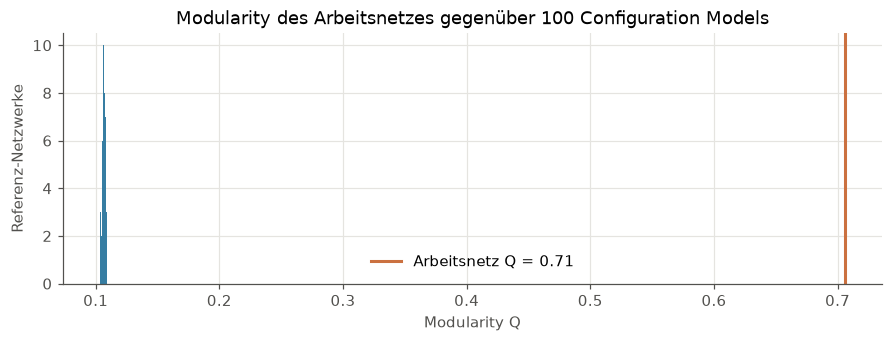

In [7]:
louvain_unweighted = nx_comm.louvain_communities(G_work, weight=None, seed=SEED)
q_observed = nx_comm.modularity(G_work, louvain_unweighted, weight=None)
degrees = [degree for _, degree in G_work.degree()]

q_reference = []
for i in range(N_REFERENCE):
    reference = nx.Graph(nx.configuration_model(degrees, seed=SEED + i))
    reference.remove_edges_from(nx.selfloop_edges(reference))
    partition = nx_comm.louvain_communities(reference, weight=None, seed=SEED)
    q_reference.append(nx_comm.modularity(reference, partition, weight=None))
q_reference = np.array(q_reference)
p_value = (q_reference >= q_observed).mean()

display(pd.Series({
    'Q Arbeitsnetz (ungewichtet)': f'{q_observed:.3f}',
    'Q Referenz-Netzwerke (Mittel)': f'{q_reference.mean():.3f}',
    'Q Referenz-Netzwerke (Maximum)': f'{q_reference.max():.3f}',
    'p-Wert': f'< {1 / N_REFERENCE:.2f}' if p_value == 0 else f'{p_value:.2f}',
}, name='Modularity-Test').to_frame())

fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.hist(q_reference, bins=20, color=COLOR)
ax.axvline(q_observed, color='#cb7140', linewidth=2, label=f'Arbeitsnetz Q = {q_observed:.2f}')
ax.set(xlabel='Modularity Q', ylabel='Referenz-Netzwerke',
       title='Modularity des Arbeitsnetzes gegenüber 100 Configuration Models')
ax.legend(frameon=False)
plt.show()

Ungewichtet erreicht das Arbeitsnetz Q = 0.706, die 100 Referenz-Netzwerke im Mittel 0.107 und höchstens 0.110. Keines erreicht den beobachteten Wert (p < 0.01). Die Community-Struktur geht damit weit über das hinaus, was die Gradverteilung allein erzeugt. Mit 100 Referenz-Netzwerken ist p < 0.01 die feinste Aussage; der Abstand ist aber so gross, dass mehr Wiederholungen am Ergebnis nichts ändern würden.

## 5.6 Communities und Nationen

In Kapitel 4 zeigte der Hypothesentest eine deutliche nationale Prägung der Kanten. Hier prüfen wir, wie stark Communities mit Nationen übereinstimmen und wo Michael Phelps und die Schweizer Athleten liegen.

In [8]:
nation = athletes['athlete_nation']
dominant_nation = nation.groupby(louvain_label).agg(
    lambda s: s.value_counts().sort_index().sort_values(ascending=False, kind='stable').index[0]
)
in_own_nation_community = nation.eq(louvain_label.map(dominant_nation))
nation_spread = louvain_label.groupby(nation).agg(lambda s: s.value_counts(normalize=True).iloc[0])
national_communities = profile[profile['Anteil dominante Nation'] >= 0.9]

display(pd.Series({
    'Athleten in einer von ihrer Nation dominierten Community': f'{in_own_nation_community.mean():.1%}',
    'Anteil einer Nation in ihrer grössten Community (Median)': f'{nation_spread.median():.0%}',
    'Communities ab 150 Athleten mit >= 90 % einer Nation': f'{len(national_communities)}',
}, name='Communities und Nationen').to_frame())
display(national_communities[['Athleten', 'Dominante Nation', 'Anteil dominante Nation']]
        .assign(**{'Anteil dominante Nation': lambda d: d['Anteil dominante Nation'].map('{:.0%}'.format)}))

phelps = athletes.index[athletes['athlete_name'].eq('PHELPS, Michael')][0]
print(f'Michael Phelps: Community {louvain_label[phelps]}')

swiss = nation.index[nation.eq('Switzerland')]
display(louvain_label[swiss].value_counts().head(5).rename('Schweizer Athleten').to_frame()
        .join(profile[['Dominante Nation', 'Median Geburtsjahr']]))

,Communities und Nationen
Athleten in einer von ihrer Nation dominierten Community,45.7%
Anteil einer Nation in ihrer grössten Community (Median),50%
Communities ab 150 Athleten mit >= 90 % einer Nation,11


,Athleten,Dominante Nation,Anteil dominante Nation
C8,200,Spain,90%
C9,185,Türkiye,99%
C10,182,Serbia,97%
C12,180,Poland,98%
C15,176,Slovakia,93%
C17,171,Norway,98%
C18,169,Latvia,92%
C20,167,Austria,96%
C21,167,New Zealand,94%
C22,165,Ireland,98%


Michael Phelps: Community C2


,Schweizer Athleten,Dominante Nation,Median Geburtsjahr
louvain,,,
C19,101,Switzerland,2000.0
C2,27,South Africa,1988.0
C4,18,Ukraine,1978.0
C1,4,Australia,2002.0
C5,3,Belgium,2000.0


45.7 % der Athleten liegen in einer Community, die von ihrer eigenen Nation dominiert wird, und eine Nation hat im Median die Hälfte ihrer Athleten in derselben Community. Das entspricht der nationalen Prägung aus Kapitel 4: Wer vor allem national startet, bleibt in der nationalen Community, international startende Athleten wechseln in die Generationen.

Michael Phelps gehört zu C2, der Generation um die Weltmeisterschaft 2009. Von den 160 Schweizern liegen 101 in C19, zusammen mit Athleten aus Zypern und Liechtenstein, 27 in C2 und 18 in C4. Das bestätigt die Contextual View: Die Mehrheit ist national vernetzt, die international startenden Schweizer verteilen sich auf die Generationen.

## 5.7 Communities im Nationennetz

Auf dem Nationennetz aus Kapitel 4 (182 Nationen, Kantengewicht = gemeinsame Tage der Athletenpaare) suchen wir ebenfalls Communities mit Louvain.

In [9]:
N = nx.Graph()
nations_graph = nx.read_gexf(NETWORK_DIR / 'nations.gexf')
N.add_nodes_from(sorted(nations_graph.nodes(data=True)))
N.add_edges_from(nations_graph.edges(data=True))

nation_communities = sorted(nx_comm.louvain_communities(N, weight='weight', seed=SEED),
                            key=lambda members: (-len(members), min(members)))
q_nations = nx_comm.modularity(N, nation_communities, weight='weight')
print(f'Nationennetz: Modularity Q = {q_nations:.3f}, {len(nation_communities)} Communities')

display(pd.DataFrame([{
    'Nationen': len(members),
    'Athleten': sum(N.nodes[name]['n_athletes'] for name in members),
    'Grösste Nationen': ', '.join(sorted(members, key=lambda name: -N.nodes[name]['n_athletes'])[:8]),
} for members in nation_communities], index=[f'N{i}' for i in range(1, len(nation_communities) + 1)]))

Nationennetz: Modularity Q = 0.199, 5 Communities


,Nationen,Athleten,Grösste Nationen
N1,87,2644,"Mexico, Egypt, Argentina, Venezuela, Tunisia, ..."
N2,50,6911,"Spain, Italy, Great Britain, Russia, France, G..."
N3,40,3438,"United States, China, Hong Kong, Japan, Austra..."
N4,4,162,"Portugal, Angola, Mozambique, Malawi"
N5,1,1,St. Kitts & Nevis


Mit Q = 0.199 liegt die Modularity unter 0.3, die Struktur ist schwach. Das passt zur hohen Density des Nationennetzes, da internationale Meisterschaften fast alle Nationen verbinden. Die Gruppen sind dennoch plausibel: Europa (N2), Asien-Pazifik zusammen mit den grossen Schwimmnationen USA, Kanada, Australien, Brasilien und Südafrika (N3) sowie viele kleinere Schwimmnationen aus Lateinamerika, Karibik, Afrika und dem Nahen Osten (N1). Portugal bildet mit Angola, Mosambik und Malawi eine eigene Gruppe (N4), St. Kitts und Nevis ist isoliert.

## 5.8 Export

Die Zuordnungen werden für spätere Kapitel gespeichert (Zentralität je Community, Link Prediction, Diffusion). Für die Darstellung in Gephi enthält eine CSV-Datei die vier grössten Communities; alle anderen Athleten erhalten die Kategorie `Übrige`.

Die Abbildung im Report (`Report/graphics/Athletes_Communities.png`) entsteht in Gephi: Layout wie in Abbildung 3.2, Färbung nach der Spalte `community` mit den Farben aus `COMMUNITY_COLORS`.

In [10]:
assignments = pd.concat([louvain_label, lpa_label, core_number], axis=1)
assignments.index.name = 'node'
assignments.reset_index().to_parquet(NETWORK_DIR / 'athlete_communities.parquet', index=False)

gephi = pd.DataFrame({
    'Id': louvain_label.index,
    'community': louvain_label.where(louvain_label.isin(COMMUNITY_COLORS), 'Übrige').to_numpy(),
})
gephi.to_csv(NETWORK_DIR / 'athlete_communities_gephi.csv', index=False)
display(gephi['community'].value_counts().to_frame('Athleten')
        .assign(Farbe=lambda d: d.index.map(lambda c: COMMUNITY_COLORS.get(c, OTHER_COLOR))))

,Athleten,Farbe
community,,
Übrige,6732,#c9c8c3
C1,2064,#8cb900
C2,1881,#eb6834
C3,1304,#1baf7a
C4,1175,#c13a8a
